# A neural network learns addition (2 + 2)

This notebook implements **feedforward** and **backpropagation** step by step, exactly as derived by hand. Variable names match the math symbols.

## Architecture

| Symbol | Meaning | Shape |
|---|---|---|
| $x$ | input (2 inputs, no bias) | $2\times1$ |
| $W^{(1)}$ | weights input -> hidden | $3\times2$ |
| $a^{(1)}=f(z^{(1)})$ | hidden layer (3 neurons) | $3\times1$ |
| $W^{(2)}$ | weights hidden -> output | $1\times3$ |
| $a^{(2)}=f(z^{(2)})=\hat{y}$ | output (1 neuron) | $1\times1$ |

## Feedforward
$$z^{(1)} = W^{(1)} x, \quad a^{(1)} = f(z^{(1)}), \quad z^{(2)} = W^{(2)} a^{(1)}, \quad a^{(2)} = f(z^{(2)}) = \hat{y}$$

## Cost
$$C = \tfrac{1}{2}(y - \hat{y})^2$$

## Backpropagation (chain rule + Hadamard product $\odot$)
$$\delta^{(2)} = f'(z^{(2)}) \odot \frac{\partial C}{\partial a^{(2)}}, \qquad \frac{\partial C}{\partial W^{(2)}} = \delta^{(2)} \,(a^{(1)})^T$$
$$\delta^{(1)} = f'(z^{(1)}) \odot \big( (W^{(2)})^T \delta^{(2)} \big), \qquad \frac{\partial C}{\partial W^{(1)}} = \delta^{(1)} \, x^T$$

## Update rule (learning rate / step size $\alpha$)
$$W^{(2)} \leftarrow W^{(2)} + \alpha \frac{\partial C}{\partial W^{(2)}}, \qquad W^{(1)} \leftarrow W^{(1)} + \alpha \frac{\partial C}{\partial W^{(1)}}$$

The $+$ works because $\frac{\partial C}{\partial a^{(2)}}$ is taken as $(y - \hat{y})$: the minus sign of the derivative is folded in. Identical to the usual $W \leftarrow W - \alpha \nabla C$.

## 1) Activation function $f$ and its derivative $f'$

Default here: **identity** ($f(z)=z$, $f'(z)=1$), so the net learns addition exactly. Switch to `"sigmoid"` to experiment (see `xor_nn.py` for where sigmoid is actually needed).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

ACTIVATION = "identity"   # "identity" or "sigmoid"

def f(z):
    if ACTIVATION == "identity":
        return z
    return 1.0 / (1.0 + np.exp(-z))           # sigmoid

def f_prime(z):
    if ACTIVATION == "identity":
        return np.ones_like(z)
    s = f(z)
    return s * (1.0 - s)                       # sigmoid'

## 2) Initialise the weights

$W^{(1)}$ is $3\times2$, $W^{(2)}$ is $1\times3$. No bias.

In [2]:
rng = np.random.default_rng(0)
W1 = rng.standard_normal((3, 2)) * 0.1   # 3x2
W2 = rng.standard_normal((1, 3)) * 0.1   # 1x3
print("W1 (shape", W1.shape, "):\n", W1)
print("W2 (shape", W2.shape, "):\n", W2)

W1 (shape (3, 2) ):
 [[ 0.01257302 -0.01321049]
 [ 0.06404227  0.01049001]
 [-0.05356694  0.03615951]]
W2 (shape (1, 3) ):
 [[ 0.1304      0.0947081  -0.07037352]]


## 3) A single feedforward pass

We send $x = \binom{2}{2}$ through the net and look at all intermediate values $z^{(1)}, a^{(1)}, z^{(2)}, a^{(2)}$.

In [3]:
x = np.array([[2.0], [2.0]])   # 2x1

z1 = W1 @ x      # 3x2 . 2x1 -> 3x1
a1 = f(z1)       # 3x1
z2 = W2 @ a1     # 1x3 . 3x1 -> 1x1
a2 = f(z2)       # 1x1 = y_hat

print("z1 (3x1):\n", z1)
print("a1 (3x1):\n", a1)
print("z2 (1x1):", z2)
print("a2 = y_hat:", a2, " (still wrong before training -- target is 4)")

z1 (3x1):
 [[-0.00127493]
 [ 0.14906455]
 [-0.03481486]]
a1 (3x1):
 [[-0.00127493]
 [ 0.14906455]
 [-0.03481486]]
z2 (1x1): [[0.01640141]]
a2 = y_hat: [[0.01640141]]  (still wrong before training -- target is 4)


## 4) A single backpropagation step

Exactly the formulas above. `*` is the **Hadamard product** $\odot$ (element-wise).

In [4]:
y = np.array([[4.0]])   # target output for 2+2

dC_da2 = (y - a2)                          # 1x1  (minus sign folded in -> '+' update)
delta2 = f_prime(z2) * dC_da2              # 1x1
dC_dW2 = delta2 @ a1.T                     # 1x1 . 1x3 -> 1x3  (shape of W2)

delta1 = f_prime(z1) * (W2.T @ delta2)     # 3x1
dC_dW1 = delta1 @ x.T                      # 3x1 . 1x2 -> 3x2  (shape of W1)

print("delta2 (1x1):", delta2)
print("dC_dW2 (1x3):\n", dC_dW2)
print("delta1 (3x1):\n", delta1)
print("dC_dW1 (3x2):\n", dC_dW1)

delta2 (1x1): [[3.98359859]]
dC_dW2 (1x3):
 [[-0.0050788   0.59381334 -0.13868844]]
delta1 (3x1):
 [[ 0.51946127]
 [ 0.37727904]
 [-0.28033987]]
dC_dW1 (3x2):
 [[ 1.03892255  1.03892255]
 [ 0.75455808  0.75455808]
 [-0.56067974 -0.56067974]]


## 5) Training loop

Many examples $x = (x_1, x_2)$ with target $y = x_1 + x_2$. Per example: feedforward -> backprop -> update. The learning rate $\alpha$ shrinks over time.

In [5]:
# Fresh weights
rng = np.random.default_rng(0)
W1 = rng.standard_normal((3, 2)) * 0.1
W2 = rng.standard_normal((1, 3)) * 0.1

# Training data
X = rng.uniform(0, 10, size=(40, 2))
Y = X.sum(axis=1, keepdims=True)

ALPHA0 = 0.001
EPOCHS = 200
loss_history = []

for epoch in range(EPOCHS):
    alpha = ALPHA0 / (1.0 + epoch / 1000.0)   # shrink the learning rate
    cost_sum = 0.0
    for i in range(len(X)):
        x = X[i].reshape(2, 1)
        y = Y[i].reshape(1, 1)
        # Feedforward
        z1 = W1 @ x; a1 = f(z1); z2 = W2 @ a1; a2 = f(z2)
        cost_sum += 0.5 * float(((y - a2) ** 2).item())
        # Backprop
        delta2 = f_prime(z2) * (y - a2)
        dC_dW2 = delta2 @ a1.T
        delta1 = f_prime(z1) * (W2.T @ delta2)
        dC_dW1 = delta1 @ x.T
        # Update
        W2 = W2 + alpha * dC_dW2
        W1 = W1 + alpha * dC_dW1
    loss_history.append(cost_sum / len(X))

print("cost at start:", round(loss_history[0], 5))
print("cost at end:  ", round(loss_history[-1], 8))

cost at start: 36.80232
cost at end:   0.0


## 6) Test: does the net add now?

In [6]:
def predict(a, b):
    x = np.array([[a], [b]], dtype=float)
    z1 = W1 @ x; a1 = f(z1); z2 = W2 @ a1; a2 = f(z2)
    return float(a2.item())

for a, b in [(2, 2), (3, 5), (7, 1), (0, 0), (9, 6), (31, 12)]:
    print(f"  {a} + {b} = {predict(a, b):6.3f}   (correct: {a + b})")

print("\nLearned weights:")
print("W1 =\n", np.round(W1, 3))
print("W2 =\n", np.round(W2, 3))
if ACTIVATION == "identity":
    print("W2 @ W1 =", np.round(W2 @ W1, 3), " (should be ~ [[1, 1]])")

  2 + 2 =  4.000   (correct: 4)
  3 + 5 =  8.000   (correct: 8)
  7 + 1 =  8.000   (correct: 8)
  0 + 0 =  0.000   (correct: 0)
  9 + 6 = 15.000   (correct: 15)
  31 + 12 = 43.000   (correct: 43)

Learned weights:
W1 =
 [[ 0.502  0.533]
 [ 0.581  0.584]
 [-0.338 -0.282]]
W2 =
 [[ 0.74   0.825 -0.44 ]]
W2 @ W1 = [[1. 1.]]  (should be ~ [[1, 1]])


## 7) Learning curve

Backpropagation drives the cost $C$ down over the epochs.

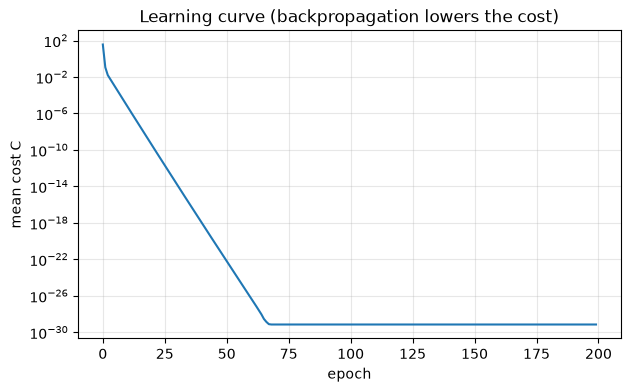

In [7]:
plt.figure(figsize=(7, 4))
plt.plot(loss_history)
plt.xlabel("epoch")
plt.ylabel("mean cost C")
plt.title("Learning curve (backpropagation lowers the cost)")
plt.yscale("log")
plt.grid(True, alpha=0.3)
plt.show()

## 8) For comparison: the same task in Keras

Keras does feedforward and backpropagation **internally** -- the formulas above are no longer visible. The result is the same.

In [8]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

np.random.seed(0)
tf.random.set_seed(0)
Xk = np.random.uniform(0, 10, size=(2000, 2))
Yk = Xk.sum(axis=1, keepdims=True)

model = keras.Sequential([
    keras.Input(shape=(2,)),
    layers.Dense(3, activation="linear", use_bias=False),
    layers.Dense(1, activation="linear", use_bias=False),
])
model.compile(optimizer=keras.optimizers.Adam(0.05), loss="mse")
model.fit(Xk, Yk, epochs=200, batch_size=32, verbose=0)

pred = float(model.predict(np.array([[2, 2]], dtype=float), verbose=0)[0, 0])
print(f"Keras:        2 + 2 = {pred:.4f}")
print(f"From scratch: 2 + 2 = {predict(2, 2):.4f}")

Keras:        2 + 2 = 4.0000
From scratch: 2 + 2 = 4.0000
